# Step 1: Problem Framing & Theory Notes

## 1. Why is Accuracy a terrible metric for fraud detection?

Accuracy is misleading for a highly imbalanced dataset. If 99.83% of transactions are legitimate and a model predicts every transaction as “Not Fraud,” its accuracy is 99.83%, but it detects no fraud. Fraud-class recall is 0%. Precision is undefined because the model predicts no transactions as fraud (many implementations report 0 when `zero_division=0`). Use fraud-class Precision, Recall, F1-score, and PR-AUC in addition to accuracy.

## 2. What is the Precision–Recall tradeoff?

- **Precision** = TP / (TP + FP): the proportion of flagged transactions that are actually fraud.
- **Recall** = TP / (TP + FN): the proportion of actual fraud cases detected.

| Actual / Predicted | Predicted Fraud | Predicted Legitimate |
|---|---|---|
| Actual Fraud | True Positive (TP) | False Negative (FN) |
| Actual Legitimate | False Positive (FP) | True Negative (TN) |

Lowering the classification threshold from 0.5 to 0.2 generally flags more transactions as fraud. Recall usually increases because fewer fraud cases are missed, while precision may decrease because more legitimate transactions are flagged as false positives.

## 3. Explain three strategies to handle extreme class imbalance

- **Random undersampling:** Removes some majority-class legitimate examples. It reduces training time but may discard useful information.
- **SMOTE oversampling:** Creates synthetic minority-class examples from nearby fraud examples. It can help the model learn fraud patterns but synthetic examples may not fully represent real fraud. Apply SMOTE only to training data.
- **`class_weight='balanced'`:** Gives greater weight to errors on the minority class while retaining the original rows. It is straightforward, but may increase false positives and does not guarantee the best Precision–Recall balance.

## 4. What is PR-AUC, and why is it preferred over ROC-AUC for extreme imbalance?

PR-AUC summarises the Precision–Recall curve across classification thresholds. It focuses on the positive fraud class and shows the tradeoff between catching fraud and generating false alarms. ROC-AUC can look strong on imbalanced data even when false positives are large compared with the small number of fraud cases, so PR-AUC is often more informative for this task.

## 5. Which is more costly: False Positive or False Negative?

A **False Negative** misses a real fraudulent transaction and can cause direct financial loss, chargebacks, and loss of customer trust. A **False Positive** flags a legitimate transaction, potentially declining or delaying a genuine payment and creating investigation work. In this practical, the assumed average fraud value is ₹4,500 and the cost of investigating a flagged transaction is ₹150. The best threshold should balance missed-fraud losses, investigation cost, customer experience, and operational capacity.

---



## 2.1 Load & Sample

Load `creditcard.csv`, print its shape and class distribution, create a stratified 50,000-row sample using `random_state=42`, verify that the fraud ratio is preserved, and describe the `Time` and `Amount` columns.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv("creditcard.csv")

# Display dataset shape
print("Original Dataset Shape:", df.shape)

# Check class distribution
print("\nOriginal Class Counts:")
print(df["Class"].value_counts())

print("\nOriginal Class Distribution:")
print(df["Class"].value_counts(normalize=True))

# Create stratified sample of 50,000 rows
y = df["Class"]

sample_df, _ = train_test_split(
    df,
    train_size=50000,
    stratify=y,
    random_state=42
)

sample_df = sample_df.reset_index(drop=True)

# Confirm sample shape
print("\nSample Dataset Shape:", sample_df.shape)

# Check sample class counts
print("\nSample Class Counts:")
print(sample_df["Class"].value_counts())

# Check sample fraud ratio
print("\nSample Class Distribution:")
print(sample_df["Class"].value_counts(normalize=True))

# Descriptive statistics for Time and Amount
print("\nDescriptive Statistics for Time and Amount:")
print(sample_df[["Time", "Amount"]].describe())

Original Dataset Shape: (284807, 31)

Original Class Counts:
Class
0    284315
1       492
Name: count, dtype: int64

Original Class Distribution:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

Sample Dataset Shape: (50000, 31)

Sample Class Counts:
Class
0    49914
1       86
Name: count, dtype: int64

Sample Class Distribution:
Class
0    0.99828
1    0.00172
Name: proportion, dtype: float64

Descriptive Statistics for Time and Amount:
               Time        Amount
count   50000.00000  50000.000000
mean    94977.93554     86.942063
std     47475.50731    226.984602
min         0.00000      0.000000
25%     54423.50000      5.850000
50%     84852.00000     22.000000
75%    139392.25000     76.275000
max    172787.00000   8360.000000


## 2.2 Target & Feature Analysis — Class Distribution

Plot the `Class` column as a countplot and use a logarithmic y-axis to show class imbalance.

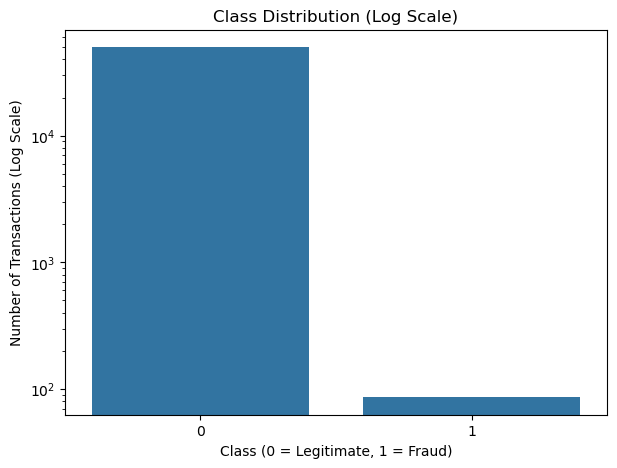

In [2]:
plt.figure(figsize=(7, 5))

sns.countplot(data=sample_df, x="Class")

plt.yscale("log")
plt.title("Class Distribution (Log Scale)")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions (Log Scale)")

plt.show()

## 2.2 Target & Feature Analysis — Amount Distribution

Compare transaction Amount distributions for Fraud (`Class = 1`) and Legitimate (`Class = 0`) transactions.

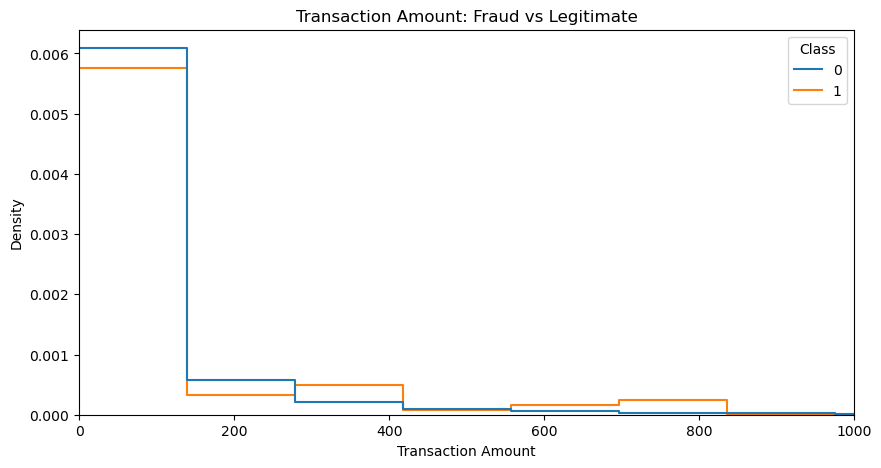

In [3]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=sample_df,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

# Limit the x-axis to make the main distribution easier to see
plt.xlim(0, sample_df["Amount"].quantile(0.99))

plt.title("Transaction Amount: Fraud vs Legitimate")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.show()

## 2.2 Target & Feature Analysis — Time Distribution

Compare transaction Time distributions for Fraud and Legitimate transactions.

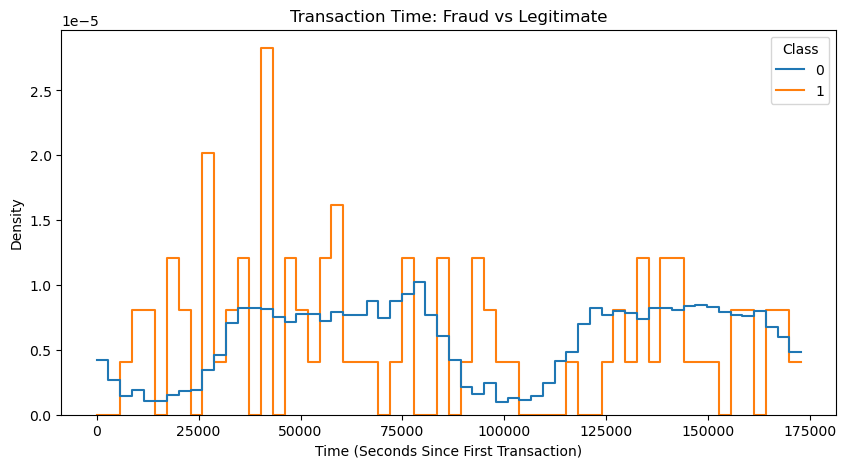

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=sample_df,
    x="Time",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Transaction Time: Fraud vs Legitimate")
plt.xlabel("Time (Seconds Since First Transaction)")
plt.ylabel("Density")

plt.show()

## 2.2 Target & Feature Analysis — Correlation Heatmap

Plot correlations between `V1`–`V10` and `Class`, then identify the V-features most correlated with fraud.

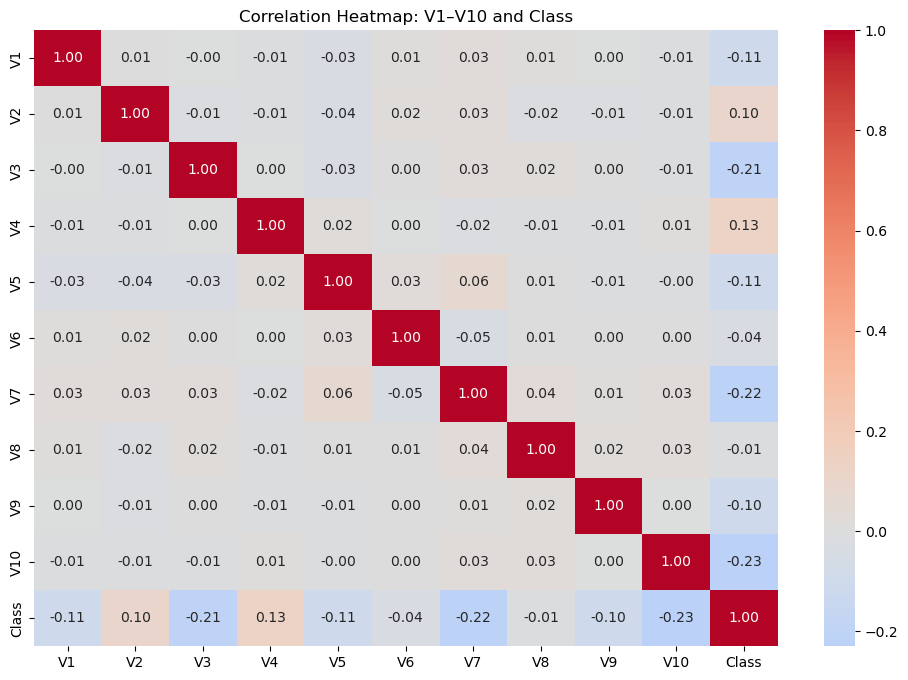


Features Most Correlated with Fraud:
V10   -0.229868
V7    -0.216016
V3    -0.205368
V4     0.130889
V5    -0.107581
V1    -0.107532
V9    -0.104933
V2     0.099175
V6    -0.036334
V8    -0.009454
Name: Class, dtype: float64


In [5]:
# Select V1 to V10 and the target column
columns = [f"V{i}" for i in range(1, 11)] + ["Class"]

# Calculate correlations
correlation = sample_df[columns].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap: V1–V10 and Class")

plt.show()

# Display features most correlated with fraud
print("\nFeatures Most Correlated with Fraud:")

fraud_corr = correlation["Class"].drop("Class")

print(
    fraud_corr.reindex(
        fraud_corr.abs().sort_values(ascending=False).index
    )
)

## 3.1 Feature Engineering

Create `Amount_log = log1p(Amount)` and `Hour = (Time % 86400) // 3600`, then drop the original `Time` and `Amount` columns.

In [6]:
import numpy as np

# Create a copy of the sampled dataset
data = sample_df.copy()

# 1. Create Amount_log
data["Amount_log"] = np.log1p(data["Amount"])

# 2. Create Hour from Time
data["Hour"] = (data["Time"] % 86400) // 3600

# 3. Drop original Time and Amount columns
data.drop(["Time", "Amount"], axis=1, inplace=True)

# Display the first 5 rows
print("Dataset after Feature Engineering:")
print(data.head())

# Display dataset shape
print("\nDataset Shape:", data.shape)

# Display column names
print("\nRemaining Columns:")
print(data.columns.tolist())

Dataset after Feature Engineering:
         V1        V2        V3        V4        V5        V6        V7  \
0 -1.370413  1.095589 -0.668018 -0.024219  1.675652  3.823629 -0.634559   
1  1.805238  0.961264 -1.717212  4.094625  0.938666 -0.227785  0.152911   
2 -1.789123  0.941366  1.432897 -1.318458 -0.450124 -1.290731  0.933642   
3 -0.711379 -1.431688  0.630874 -2.551985  0.509280 -0.565154  0.258866   
4  1.303287  1.023966 -3.187599  0.468391  3.353988  2.431416  0.184510   

         V8        V9       V10  ...       V22       V23       V24       V25  \
0  1.836666 -0.485368 -0.547920  ... -0.609795  0.027077  0.986022  0.079739   
1  0.066753 -1.073784  0.334537  ... -0.450959  0.098530 -0.662272 -0.150154   
2 -0.306360  0.917978  0.722699  ... -0.202022 -0.017159  0.740137 -0.183085   
3 -0.289951 -2.680067  1.154872  ... -1.064836  0.435373 -0.932473 -0.459677   
4  0.622721 -0.556254 -1.485591  ... -0.823366 -0.241908  0.674554  1.012236   

        V26       V27       V28  

## Setup — Install imbalanced-learn

Install the package required for SMOTE and random undersampling.

In [7]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


## 3.2 Scaling & 3.3 Train-Test Split

Apply `StandardScaler` to `Amount_log` and `Hour` only. Split the data into 80% training and 20% testing using stratification and `random_state=42`.

In [8]:
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = data.drop("Class", axis=1)
y = data["Class"]

# Split the data into 80% training and 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Apply StandardScaler only to Amount_log and Hour
scaler = StandardScaler()

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

# Fit the scaler on training data only
X_train[["Amount_log", "Hour"]] = scaler.fit_transform(
    X_train_raw[["Amount_log", "Hour"]]
)

# Transform test data using the same fitted scaler
X_test[["Amount_log", "Hour"]] = scaler.transform(
    X_test_raw[["Amount_log", "Hour"]]
)

print("Scaling completed successfully!")
print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Scaling completed successfully!

Training features shape: (40000, 30)
Testing features shape: (10000, 30)


## 3.3 Train-Test Split — Verify Class Distribution

Print class counts and class proportions for both training and test sets to confirm stratification preserved the fraud ratio.

In [9]:
# Training dataset class distribution
print("Training Set Class Counts:")
print(y_train.value_counts().sort_index())

print("\nTraining Set Class Distribution:")
print(y_train.value_counts(normalize=True).sort_index())

# Testing dataset class distribution
print("\nTesting Set Class Counts:")
print(y_test.value_counts().sort_index())

print("\nTesting Set Class Distribution:")
print(y_test.value_counts(normalize=True).sort_index())

# Display the fraud percentage
print("\nFraud percentage in training set:",
      round((y_train == 1).mean() * 100, 4), "%")

print("Fraud percentage in testing set:",
      round((y_test == 1).mean() * 100, 4), "%")

Training Set Class Counts:
Class
0    39931
1       69
Name: count, dtype: int64

Training Set Class Distribution:
Class
0    0.998275
1    0.001725
Name: proportion, dtype: float64

Testing Set Class Counts:
Class
0    9983
1      17
Name: count, dtype: int64

Testing Set Class Distribution:
Class
0    0.9983
1    0.0017
Name: proportion, dtype: float64

Fraud percentage in training set: 0.1725 %
Fraud percentage in testing set: 0.17 %


## 3.4 Imbalance Handling — Three Strategies

Prepare the original imbalanced training data, SMOTE training data (`sampling_strategy=0.1`), and random-undersampled training data (`sampling_strategy=0.1`). Compare class counts.

In [17]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import pandas as pd

# 1. Original training data (imbalanced)
X_original = X_train.copy()
y_original = y_train.copy()

# 2. SMOTE Oversampling
smote = SMOTE(
    random_state=42,
    sampling_strategy=0.1
)

X_smote, y_smote = smote.fit_resample(X_train, y_train)

# 3. Random Undersampling
undersampler = RandomUnderSampler(
    random_state=42,
    sampling_strategy=0.1
)

X_under, y_under = undersampler.fit_resample(X_train, y_train)

# Print class counts for all three strategies
print("1. Original Training Data:")
print(y_train.value_counts().sort_index())

print("\n2. SMOTE Training Data:")
print(pd.Series(y_smote).value_counts().sort_index())

print("\n3. Undersampled Training Data:")
print(pd.Series(y_under).value_counts().sort_index())

# Display all counts in one comparison table
comparison = pd.DataFrame({
    "Original": y_train.value_counts(),
    "SMOTE": pd.Series(y_smote).value_counts(),
    "Undersampled": pd.Series(y_under).value_counts()
}).fillna(0).astype(int).sort_index()

print("\nComparison of Class Counts:")
print(comparison)

1. Original Training Data:
Class
0    39931
1       69
Name: count, dtype: int64

2. SMOTE Training Data:
Class
0    39931
1     3993
Name: count, dtype: int64

3. Undersampled Training Data:
Class
0    690
1     69
Name: count, dtype: int64

Comparison of Class Counts:
       Original  SMOTE  Undersampled
Class                               
0         39931  39931           690
1            69   3993            69


## 4.1 Logistic Regression — Three Variants

Train Logistic Regression on the original data with `class_weight='balanced'`, SMOTE data, and undersampled data. Compare Fraud-class Precision, Recall, F1-score, and PR-AUC to identify the best strategy.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

# 1. Logistic Regression on Original Data
lr_original = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_original.fit(X_train, y_train)

# 2. Logistic Regression on SMOTE Data
lr_smote = LogisticRegression(
    class_weight=None,
    max_iter=1000,
    random_state=42
)

lr_smote.fit(X_smote, y_smote)

# 3. Logistic Regression on Undersampled Data
lr_under = LogisticRegression(
    class_weight=None,
    max_iter=1000,
    random_state=42
)

lr_under.fit(X_under, y_under)


# Function to evaluate each model
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test, y_prob
        )
    }


# Evaluate all three Logistic Regression models
lr_results = pd.DataFrame([
    evaluate_model(
        "LR Original (Balanced)",
        lr_original, X_test, y_test
    ),
    evaluate_model(
        "LR with SMOTE",
        lr_smote, X_test, y_test
    ),
    evaluate_model(
        "LR Undersampled",
        lr_under, X_test, y_test
    )
])

# Display comparison table
print("LOGISTIC REGRESSION COMPARISON")
print(lr_results.to_string(index=False))

# Identify the best strategy using PR-AUC
best_index = lr_results["PR-AUC"].idxmax()
best_lr_name = lr_results.loc[best_index, "Model"]

lr_models = {
    "LR Original (Balanced)": lr_original,
    "LR with SMOTE": lr_smote,
    "LR Undersampled": lr_under
}

best_lr_model = lr_models[best_lr_name]

print("\nBest Logistic Regression Strategy:", best_lr_name)
print("Best PR-AUC:", lr_results.loc[best_index, "PR-AUC"])

LOGISTIC REGRESSION COMPARISON
                 Model  Precision   Recall  F1-Score   PR-AUC
LR Original (Balanced)   0.064885 1.000000  0.121864 0.781376
         LR with SMOTE   0.309091 1.000000  0.472222 0.814363
       LR Undersampled   0.228571 0.941176  0.367816 0.809281

Best Logistic Regression Strategy: LR with SMOTE
Best PR-AUC: 0.8143634239655


## 4.2 Random Forest — Best Imbalance Strategy

Train `RandomForestClassifier` using the best imbalance strategy selected from the Logistic Regression comparison. Report Precision, Recall, F1-score, and PR-AUC.

In [18]:
from sklearn.ensemble import RandomForestClassifier

# Select the training data from the best Logistic Regression strategy
if best_lr_name == "LR Original (Balanced)":
    X_rf_train, y_rf_train = X_train, y_train

elif best_lr_name == "LR with SMOTE":
    X_rf_train, y_rf_train = X_smote, y_smote

else:
    X_rf_train, y_rf_train = X_under, y_under


# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=1
)

rf_model.fit(X_rf_train, y_rf_train)


# Evaluate Random Forest
rf_result = evaluate_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test
)

print("RANDOM FOREST RESULTS")
print(pd.DataFrame([rf_result]).to_string(index=False))

RANDOM FOREST RESULTS
        Model  Precision   Recall  F1-Score  PR-AUC
Random Forest   0.933333 0.823529     0.875 0.89039


## 4.2 Random Forest — Precision-Recall Curve

Plot the Precision-Recall curve for the Random Forest model.

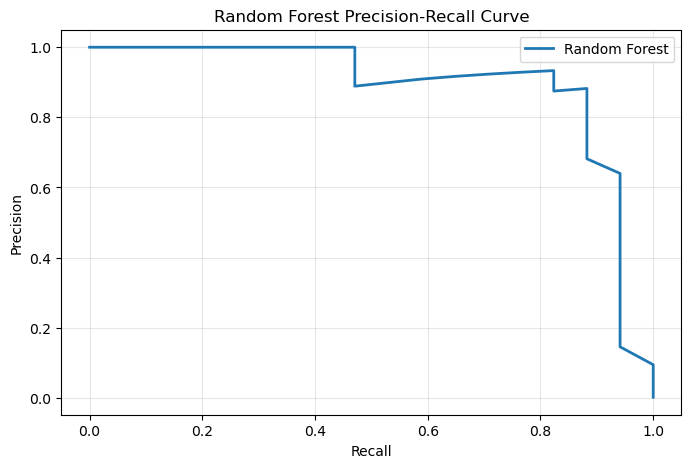

In [19]:
# Predict fraud probabilities
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(
    y_test, rf_prob
)

# Plot curve
plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label="Random Forest",
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 4.2 Random Forest — Top 15 Feature Importances

Plot and report the 15 most important features. Identify which V-features are most predictive of fraud.

TOP 15 FEATURES PREDICTIVE OF FRAUD
Feature  Importance
    V14    0.201628
    V10    0.122431
    V17    0.108907
    V12    0.081202
    V11    0.074833
     V4    0.070460
    V16    0.039718
     V3    0.033140
     V2    0.032186
     V9    0.031007
     V7    0.020964
    V21    0.020808
    V18    0.019407
    V13    0.016873
     V8    0.016394


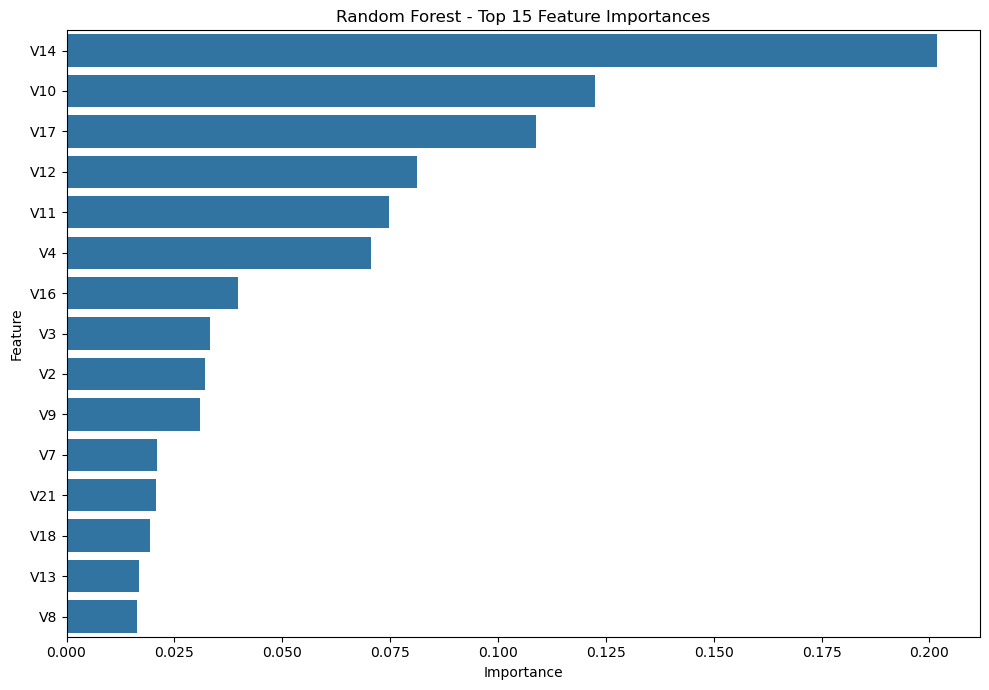

In [14]:
# Calculate feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort and select top 15 features
top15 = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(15)

print("TOP 15 FEATURES PREDICTIVE OF FRAUD")
print(top15.to_string(index=False))

# Plot feature importances
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top15,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Setup — Install XGBoost

Install the XGBoost package required for Steps 5.1 and 5.2.

In [15]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


## 5.1 XGBoost Baseline

Calculate `scale_pos_weight` as non-fraud count divided by fraud count in the original training data. Train the baseline XGBoost model and report Precision, Recall, F1-score, PR-AUC, and the Precision-Recall curve.

Non-Fraud Transactions: 39931
Fraud Transactions: 69
Scale Positive Weight: 578.7101449275362

XGBoost Baseline Model Trained Successfully!

XGBOOST BASELINE EVALUATION
--------------------------------
Precision: 1.0
Recall: 0.8235
F1-Score: 0.9032
PR-AUC: 0.8968


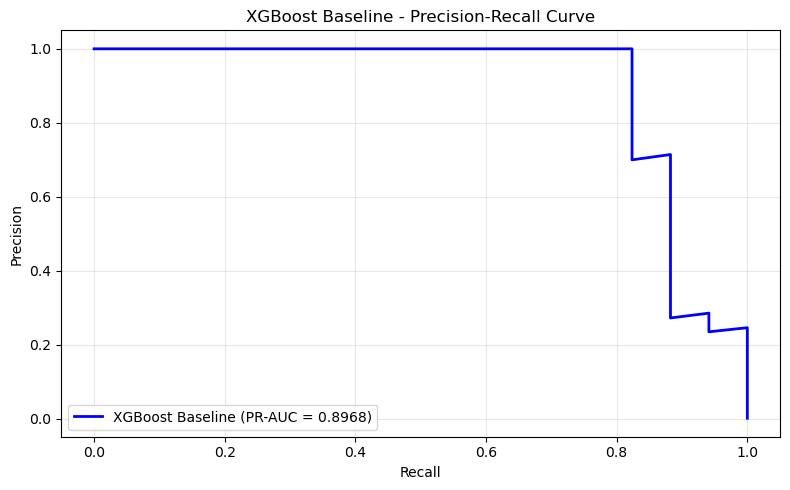

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

# 1. Calculate class imbalance ratio from original training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

ratio = negative_count / positive_count

print("Non-Fraud Transactions:", negative_count)
print("Fraud Transactions:", positive_count)
print("Scale Positive Weight:", ratio)

# 2. Train XGBoost Baseline Model
xgb_baseline = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    scale_pos_weight=ratio,
    random_state=42,
    eval_metric="aucpr",
    n_jobs=1,
    tree_method="hist"
)

xgb_baseline.fit(X_train, y_train)

print("\nXGBoost Baseline Model Trained Successfully!")

# 3. Predict on test data
y_pred = xgb_baseline.predict(X_test)
y_prob = xgb_baseline.predict_proba(X_test)[:, 1]

# 4. Calculate evaluation metrics
precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

pr_auc = average_precision_score(
    y_test, y_prob
)

# 5. Display results
print("\nXGBOOST BASELINE EVALUATION")
print("--------------------------------")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("PR-AUC:", round(pr_auc, 4))

# 6. Calculate Precision-Recall curve
pr_precision, pr_recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

# 7. Plot Precision-Recall curve
plt.figure(figsize=(8, 5))

plt.plot(
    pr_recall,
    pr_precision,
    color="blue",
    linewidth=2,
    label=f"XGBoost Baseline (PR-AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost Baseline - Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5.2 Hyperparameter Tuning

Use `RandomizedSearchCV` (`n_iter=15`, `cv=3`, `scoring='average_precision'`, `random_state=42`) to tune XGBoost. Print best parameters and CV PR-AUC, then compare baseline and tuned test PR-AUC.

Non-Fraud Count: 39931
Fraud Count: 69
Scale Positive Weight: 578.7101449275362

Starting Hyperparameter Tuning...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

BEST HYPERPARAMETERS:
{'subsample': 0.6, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

BEST CROSS-VALIDATION PR-AUC:
0.8043

Tuned XGBoost Model Trained Successfully!

TUNED XGBOOST TEST RESULTS
--------------------------------
Precision: 1.0
Recall: 0.8824
F1-Score: 0.9375
PR-AUC: 0.9364

PR-AUC COMPARISON
           Model   PR-AUC
XGBoost Baseline 0.896846
   XGBoost Tuned 0.936409


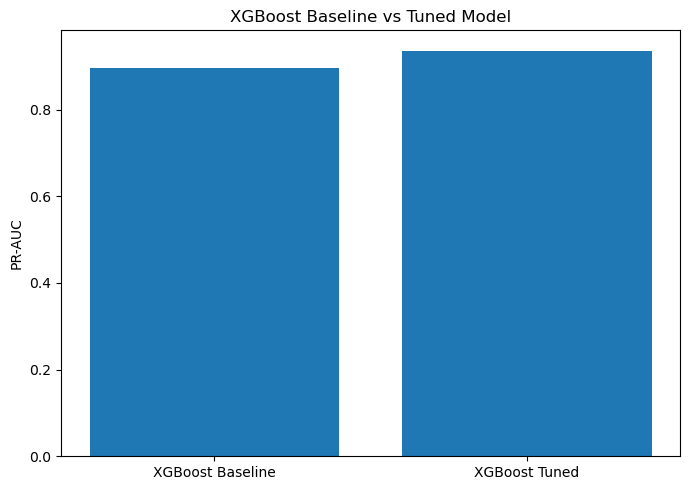

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# 1. Calculate class imbalance ratio
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

ratio = negative_count / positive_count

print("Non-Fraud Count:", negative_count)
print("Fraud Count:", positive_count)
print("Scale Positive Weight:", ratio)


# 2. Define hyperparameter search space
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0]
}


# 3. Create XGBoost model
xgb_model = XGBClassifier(
    scale_pos_weight=ratio,
    random_state=42,
    eval_metric="aucpr",
    n_jobs=1,
    tree_method="hist"
)


# 4. Configure RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring="average_precision",
    random_state=42,
    n_jobs=1,
    verbose=1
)


# 5. Perform hyperparameter tuning
print("\nStarting Hyperparameter Tuning...")

random_search.fit(X_train, y_train)

# 6. Display best parameters and CV score
print("\nBEST HYPERPARAMETERS:")
print(random_search.best_params_)

print("\nBEST CROSS-VALIDATION PR-AUC:")
print(round(random_search.best_score_, 4))


# 7. Get the tuned model
xgb_tuned = random_search.best_estimator_

print("\nTuned XGBoost Model Trained Successfully!")


# 8. Evaluate baseline model on the test set
baseline_prob = xgb_baseline.predict_proba(X_test)[:, 1]

baseline_pr_auc = average_precision_score(
    y_test, baseline_prob
)


# 9. Evaluate tuned model on the same test set
tuned_pred = xgb_tuned.predict(X_test)
tuned_prob = xgb_tuned.predict_proba(X_test)[:, 1]

tuned_precision = precision_score(
    y_test, tuned_pred, zero_division=0
)

tuned_recall = recall_score(
    y_test, tuned_pred, zero_division=0
)

tuned_f1 = f1_score(
    y_test, tuned_pred, zero_division=0
)

tuned_pr_auc = average_precision_score(
    y_test, tuned_prob
)


# 10. Print tuned model evaluation
print("\nTUNED XGBOOST TEST RESULTS")
print("--------------------------------")
print("Precision:", round(tuned_precision, 4))
print("Recall:", round(tuned_recall, 4))
print("F1-Score:", round(tuned_f1, 4))
print("PR-AUC:", round(tuned_pr_auc, 4))


# 11. Compare baseline and tuned PR-AUC
comparison = pd.DataFrame({
    "Model": ["XGBoost Baseline", "XGBoost Tuned"],
    "PR-AUC": [baseline_pr_auc, tuned_pr_auc]
})

print("\nPR-AUC COMPARISON")
print(comparison.to_string(index=False))


# 12. Plot comparison
plt.figure(figsize=(7, 5))

plt.bar(
    comparison["Model"],
    comparison["PR-AUC"]
)

plt.ylabel("PR-AUC")
plt.title("XGBoost Baseline vs Tuned Model")
plt.tight_layout()
plt.show()

## 5.3 Threshold Optimisation on the Best Model

Use predicted fraud probabilities to find the F1-optimal threshold and the highest-precision threshold that achieves Recall ≥ 0.90. Plot the Precision-Recall curve and compare threshold metrics.

F1-Optimal Threshold: 0.6816856
Maximum F1-Score: 0.9374999999995018

Threshold for Recall >= 0.90: 0.012493069
Precision at this threshold: 0.6153846153846154
Recall at this threshold: 0.9411764705882353


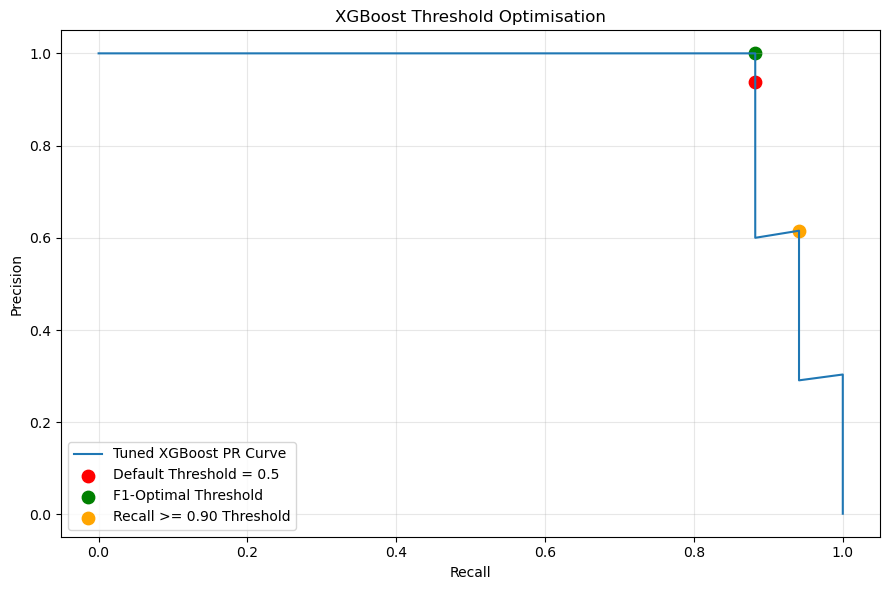


THRESHOLD COMPARISON
                   Model  Threshold  Precision   Recall  F1-Score   PR-AUC
       Default Threshold   0.500000   1.000000 0.882353  0.937500 0.936409
    F1-Optimal Threshold   0.681686   1.000000 0.882353  0.937500 0.936409
Recall >= 0.90 Threshold   0.012493   0.615385 0.941176  0.744186 0.936409


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

# 1. Get fraud probabilities from the tuned XGBoost model
y_prob = xgb_tuned.predict_proba(X_test)[:, 1]

# 2. Calculate Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

# 3. Find threshold that maximises F1-score
# The thresholds array has one fewer element than precision and recall.
p = precision[:-1]
r = recall[:-1]

f1_scores = (
    2 * p * r / (p + r + 1e-12)
)

best_f1_index = np.argmax(f1_scores)
f1_optimal_threshold = thresholds[best_f1_index]

print("F1-Optimal Threshold:", f1_optimal_threshold)
print("Maximum F1-Score:", f1_scores[best_f1_index])


# 4. Find threshold with Recall >= 0.90 and highest Precision
eligible_indices = np.where(r >= 0.90)[0]

if len(eligible_indices) > 0:
    best_recall_index = eligible_indices[
        np.argmax(p[eligible_indices])
    ]

    recall_90_threshold = thresholds[best_recall_index]

    print("\nThreshold for Recall >= 0.90:",
          recall_90_threshold)
    print("Precision at this threshold:",
          p[best_recall_index])
    print("Recall at this threshold:",
          r[best_recall_index])

else:
    recall_90_threshold = None
    print("\nNo threshold achieves Recall >= 0.90.")


# 5. Plot Precision-Recall curve and mark threshold 0.5
default_index = np.argmin(np.abs(thresholds - 0.5))

plt.figure(figsize=(9, 6))

plt.plot(
    recall,
    precision,
    label="Tuned XGBoost PR Curve"
)

plt.scatter(
    recall[default_index],
    precision[default_index],
    color="red",
    s=80,
    label="Default Threshold = 0.5"
)

plt.scatter(
    recall[best_f1_index],
    precision[best_f1_index],
    color="green",
    s=80,
    label="F1-Optimal Threshold"
)

if recall_90_threshold is not None:
    plt.scatter(
        r[best_recall_index],
        p[best_recall_index],
        color="orange",
        s=80,
        label="Recall >= 0.90 Threshold"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost Threshold Optimisation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 6. Evaluate the model at different thresholds
def evaluate_threshold(y_true, probabilities, threshold, name):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }


# Default threshold
results = [
    evaluate_threshold(
        y_test, y_prob, 0.5, "Default Threshold"
    ),

    evaluate_threshold(
        y_test, y_prob,
        f1_optimal_threshold,
        "F1-Optimal Threshold"
    )
]

# Add recall-target threshold if available
if recall_90_threshold is not None:
    results.append(
        evaluate_threshold(
            y_test, y_prob,
            recall_90_threshold,
            "Recall >= 0.90 Threshold"
        )
    )

# 7. Display comparison table
threshold_results = pd.DataFrame(results)

print("\nTHRESHOLD COMPARISON")
print(threshold_results.to_string(index=False))

## Step 6: Model Evaluation, Threshold Tuning & Comparison — Comparison Table

Compare the best Logistic Regression, Random Forest, XGBoost baseline, tuned XGBoost at threshold 0.5, tuned XGBoost at the F1-optimal threshold, and tuned XGBoost at the Recall ≥ 0.90 threshold.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

# Function to evaluate models at a given threshold
def evaluate_model_step6(name, model, X_test, y_test, threshold=0.5):

    # Predict fraud probabilities
    probabilities = model.predict_proba(X_test)[:, 1]

    # Convert probabilities into class predictions
    predictions = (probabilities >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    pr_auc = average_precision_score(
        y_test, probabilities
    )

    return {
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "PR-AUC": pr_auc,
        "Threshold": threshold
    }


# --------------------------------------------------
# 1. Create comparison table for all six variants
# --------------------------------------------------

comparison_results = []

# Logistic Regression - best strategy
comparison_results.append(
    evaluate_model_step6(
        "Logistic Regression (Best Strategy)",
        best_lr_model,
        X_test,
        y_test,
        0.5
    )
)

# Random Forest
comparison_results.append(
    evaluate_model_step6(
        "Random Forest",
        rf_model,
        X_test,
        y_test,
        0.5
    )
)

# XGBoost Baseline
comparison_results.append(
    evaluate_model_step6(
        "XGBoost Baseline",
        xgb_baseline,
        X_test,
        y_test,
        0.5
    )
)

# XGBoost Tuned - default threshold
comparison_results.append(
    evaluate_model_step6(
        "XGBoost Tuned (Default)",
        xgb_tuned,
        X_test,
        y_test,
        0.5
    )
)

# XGBoost Tuned - F1-optimal threshold
comparison_results.append(
    evaluate_model_step6(
        "XGBoost Tuned (F1-Optimal)",
        xgb_tuned,
        X_test,
        y_test,
        f1_optimal_threshold
    )
)

# XGBoost Tuned - Recall >= 0.90 threshold
if recall_90_threshold is not None:
    comparison_results.append(
        evaluate_model_step6(
            "XGBoost Tuned (Recall >= 0.90)",
            xgb_tuned,
            X_test,
            y_test,
            recall_90_threshold
        )
    )
else:
    print(
        "Warning: No threshold achieved Recall >= 0.90. "
        "The recall-target model is omitted from the table."
    )

# Convert results into DataFrame
comparison_df = pd.DataFrame(comparison_results)

print("FINAL MODEL COMPARISON TABLE")
print("=" * 100)

print(
    comparison_df.round(4).to_string(index=False)
)

# Optional: display as a formatted notebook table
display(comparison_df.round(4))

FINAL MODEL COMPARISON TABLE
                              Model  Precision  Recall  F1-Score  PR-AUC  Threshold
Logistic Regression (Best Strategy)     0.3091  1.0000    0.4722  0.8144     0.5000
                      Random Forest     0.9333  0.8235    0.8750  0.8904     0.5000
                   XGBoost Baseline     1.0000  0.8235    0.9032  0.8968     0.5000
            XGBoost Tuned (Default)     1.0000  0.8824    0.9375  0.9364     0.5000
         XGBoost Tuned (F1-Optimal)     1.0000  0.8824    0.9375  0.9364     0.6817
     XGBoost Tuned (Recall >= 0.90)     0.6154  0.9412    0.7442  0.9364     0.0125


,Model,Precision,Recall,F1-Score,PR-AUC,Threshold
0,Logistic Regression (Best Strategy),0.3091,1.0000,0.4722,0.8144,0.5000
1,Random Forest,0.9333,0.8235,0.8750,0.8904,0.5000
2,XGBoost Baseline,1.0000,0.8235,0.9032,0.8968,0.5000
3,XGBoost Tuned (Default),1.0000,0.8824,0.9375,0.9364,0.5000
4,XGBoost Tuned (F1-Optimal),1.0000,0.8824,0.9375,0.9364,0.6817
5,XGBoost Tuned (Recall >= 0.90),0.6154,0.9412,0.7442,0.9364,0.0125


## Step 6: Model Evaluation — Plot All Precision-Recall Curves

Plot the Precision-Recall curves for Logistic Regression, Random Forest, baseline XGBoost, and tuned XGBoost on one figure with a legend.

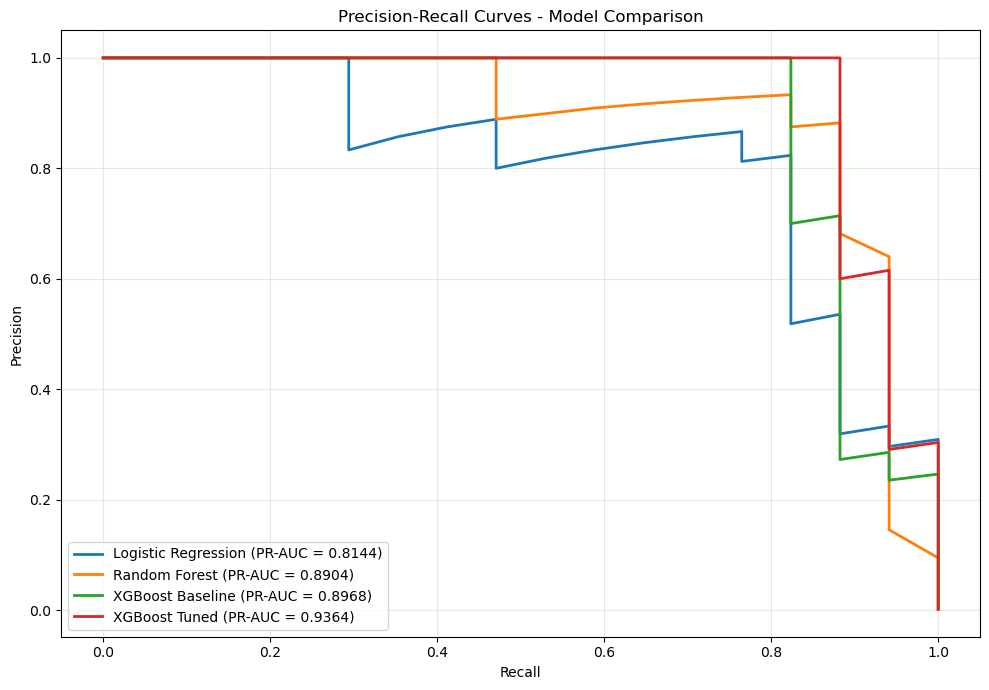

In [24]:
# --------------------------------------------------
# 2. Plot all model Precision-Recall curves
# --------------------------------------------------

models_to_plot = [
    ("Logistic Regression", best_lr_model),
    ("Random Forest", rf_model),
    ("XGBoost Baseline", xgb_baseline),
    ("XGBoost Tuned", xgb_tuned)
]

plt.figure(figsize=(10, 7))

for name, model in models_to_plot:

    # Fraud probabilities
    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate curve
    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )

    # Calculate PR-AUC
    pr_auc = average_precision_score(
        y_test, probabilities
    )

    # Plot curve
    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (PR-AUC = {pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Model Comparison")
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 6: Model Evaluation — Best Model & Deployment Recommendation

Identify the best results by F1-score and PR-AUC, then form a deployment recommendation using the measured metrics and business tradeoffs.

In [25]:
# --------------------------------------------------
# 3. Identify the best F1 and PR-AUC results
# --------------------------------------------------

best_f1_row = comparison_df.loc[
    comparison_df["F1-Score"].idxmax()
]

best_pr_auc_row = comparison_df.loc[
    comparison_df["PR-AUC"].idxmax()
]

print("\nBEST MODEL BY F1-SCORE")
print(best_f1_row.to_string())

print("\nBEST MODEL BY PR-AUC")
print(best_pr_auc_row.to_string())


# --------------------------------------------------
# 4. Recommendation based on actual results
# --------------------------------------------------

recall_rows = comparison_df[
    comparison_df["Model"] == "XGBoost Tuned (Recall >= 0.90)"
]

f1_rows = comparison_df[
    comparison_df["Model"] == "XGBoost Tuned (F1-Optimal)"
]

if not recall_rows.empty:
    recall_row = recall_rows.iloc[0]

    print("\nDEPLOYMENT RECOMMENDATION")
    print(
        f"The tuned XGBoost model achieves a recall of "
        f"{recall_row['Recall']:.4f} at threshold "
        f"{recall_row['Threshold']:.6f}. "
        f"I would consider this threshold if the business priority "
        f"is to detect at least 90% of fraudulent transactions. "
        f"Its precision is {recall_row['Precision']:.4f}, "
        f"and its F1-score is {recall_row['F1-Score']:.4f}. "
        f"The F1-optimal threshold is {f1_optimal_threshold:.6f}. "
        f"The final deployment choice should consider the false-positive "
        f"workload and the business cost of missed fraud."
    )
else:
    print(
        "\nNo Recall >= 0.90 threshold was found. "
        "Review the threshold optimisation results before deployment."
    )


BEST MODEL BY F1-SCORE
Model        XGBoost Tuned (Default)
Precision                        1.0
Recall                      0.882353
F1-Score                      0.9375
PR-AUC                      0.936409
Threshold                        0.5

BEST MODEL BY PR-AUC
Model        XGBoost Tuned (Default)
Precision                        1.0
Recall                      0.882353
F1-Score                      0.9375
PR-AUC                      0.936409
Threshold                        0.5

DEPLOYMENT RECOMMENDATION
The tuned XGBoost model achieves a recall of 0.9412 at threshold 0.012493. I would consider this threshold if the business priority is to detect at least 90% of fraudulent transactions. Its precision is 0.6154, and its F1-score is 0.7442. The F1-optimal threshold is 0.681686. The final deployment choice should consider the false-positive workload and the business cost of missed fraud.


## 7.1 Assign Transaction Costs — Cost-Benefit Analysis

Using the selected threshold and confusion matrix, calculate money saved, investigation cost, money lost, and net benefit using ₹4,500 per fraud transaction and ₹150 per flagged transaction investigation.

In [26]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# 1. Define transaction costs
FRAUD_VALUE = 4500
INVESTIGATION_COST = 150

# 2. Predict fraud probabilities using tuned XGBoost
y_prob = xgb_tuned.predict_proba(X_test)[:, 1]

# 3. Use the F1-optimal threshold from Step 5.3
optimal_threshold = f1_optimal_threshold

y_pred = (y_prob >= optimal_threshold).astype(int)

# 4. Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

print("CONFUSION MATRIX RESULTS")
print("------------------------")
print("True Positives (TP):", tp)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Negatives (TN):", tn)

# 5. Calculate business costs
money_saved = tp * FRAUD_VALUE

investigation_cost = (
    (tp + fp) * INVESTIGATION_COST
)

money_lost = fn * FRAUD_VALUE

net_benefit = (
    money_saved - investigation_cost
)

# 6. Display financial results
print("\nCOST-BENEFIT ANALYSIS")
print("---------------------")
print("Optimal Threshold:", round(optimal_threshold, 6))
print(f"Money Saved: ₹{money_saved:,.2f}")
print(f"Investigation Cost: ₹{investigation_cost:,.2f}")
print(f"Money Lost: ₹{money_lost:,.2f}")
print(f"Net Benefit: ₹{net_benefit:,.2f}")

# 7. Create a summary table
business_summary = pd.DataFrame({
    "Metric": [
        "True Positives (TP)",
        "False Positives (FP)",
        "False Negatives (FN)",
        "True Negatives (TN)",
        "Money Saved (₹)",
        "Investigation Cost (₹)",
        "Money Lost (₹)",
        "Net Benefit (₹)"
    ],
    "Value": [
        tp,
        fp,
        fn,
        tn,
        money_saved,
        investigation_cost,
        money_lost,
        net_benefit
    ]
})

print("\nBUSINESS SUMMARY TABLE")
print(business_summary.to_string(index=False))

CONFUSION MATRIX RESULTS
------------------------
True Positives (TP): 15
False Positives (FP): 0
False Negatives (FN): 2
True Negatives (TN): 9983

COST-BENEFIT ANALYSIS
---------------------
Optimal Threshold: 0.681686
Money Saved: ₹67,500.00
Investigation Cost: ₹2,250.00
Money Lost: ₹9,000.00
Net Benefit: ₹65,250.00

BUSINESS SUMMARY TABLE
                Metric  Value
   True Positives (TP)     15
  False Positives (FP)      0
  False Negatives (FN)      2
   True Negatives (TN)   9983
       Money Saved (₹)  67500
Investigation Cost (₹)   2250
        Money Lost (₹)   9000
       Net Benefit (₹)  65250
